Available Sheets: ['FactFinancialTransactions', 'ChartOfAccounts_PL', 'DimAccount', 'DimDepartment', 'DimBranch', 'DimCostCentre', 'DataDictionary', 'CaseStudy']

Loaded FactFinancialTransactions: 4500 rows, 12 columns

--- MISSING VALUES BEFORE CLEANING ---
DepartmentID    96
CostCentreID    58
dtype: int64
Duplicate TransactionIDs: 0

Saved cleaned dataset to 'cleaned_finsight_transactions.csv'

--- 2024 vs 2025 ACCOUNT BREAKDOWN (NGN) ---
         PLSection                              AccountName         2024         2025  YoY_Growth_%
           Revenue         Distribution & Handling Services  10692524.75 1.669488e+07     56.136039
           Revenue               E-Commerce & Digital Sales  36160593.78 4.402746e+07     21.755347
           Revenue          Institutional & Corporate Sales 317472352.47 4.749247e+08     49.595611
           Revenue                       Retail Store Sales 174209695.78 2.427999e+08     39.372201
           Revenue                  Wholesale Product 

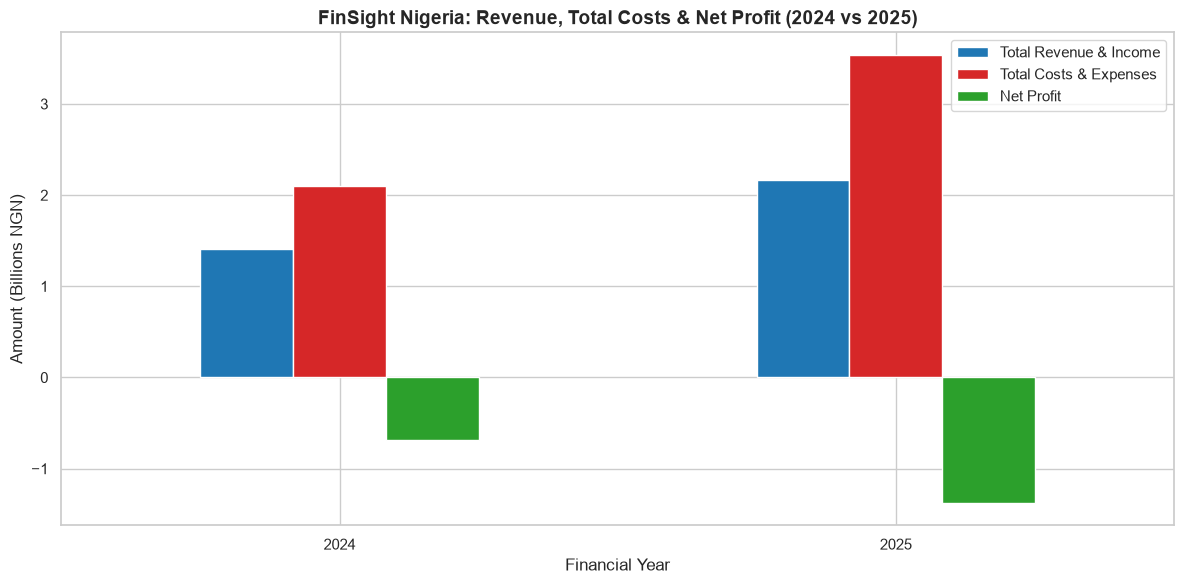

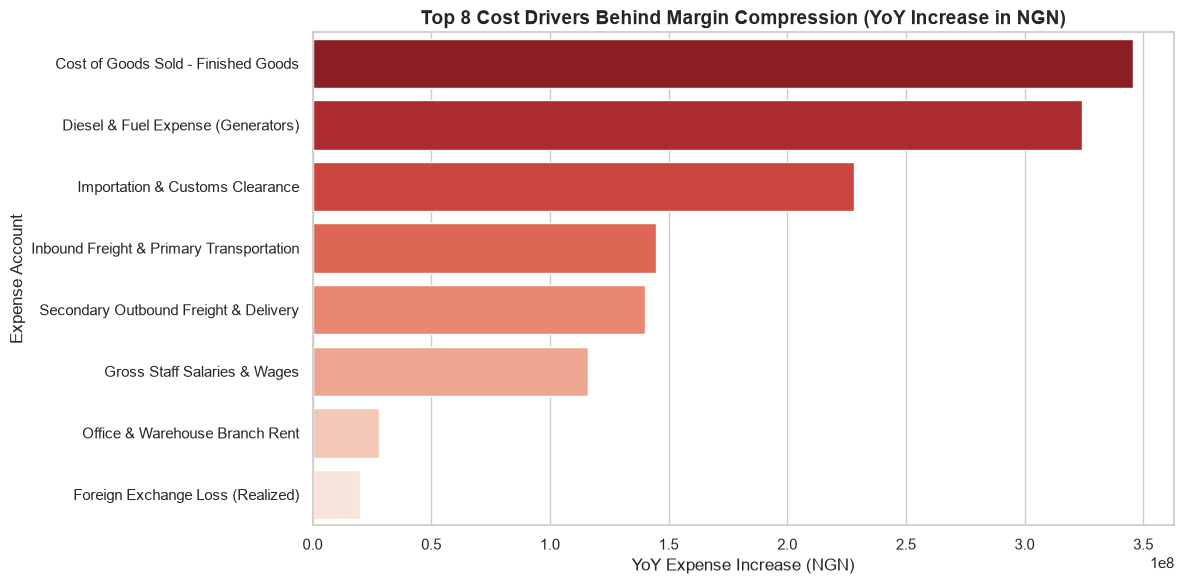

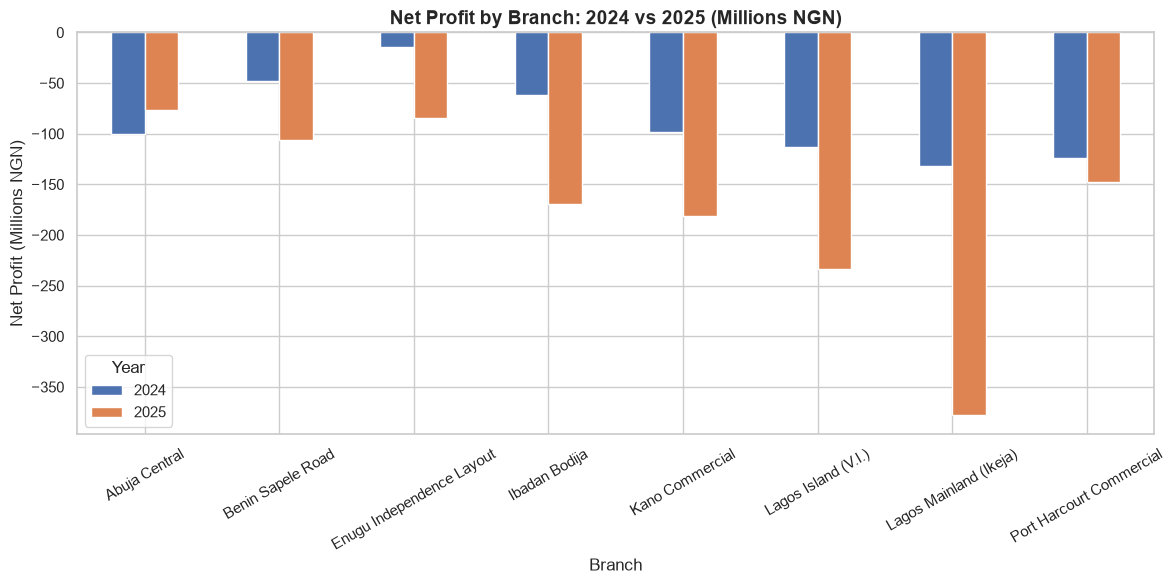


All 3 charts displayed and saved successfully!


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# 1. LOAD ALL STAR SCHEMA TABLES
file_path = "FinSight_Financial_Analytics.xlsx"
excel_data = pd.ExcelFile(file_path)
print("Available Sheets:", excel_data.sheet_names)

fact_txn = pd.read_excel(file_path, sheet_name="FactFinancialTransactions")
dim_account = pd.read_excel(file_path, sheet_name="DimAccount")
dim_dept = pd.read_excel(file_path, sheet_name="DimDepartment")
dim_branch = pd.read_excel(file_path, sheet_name="DimBranch")
dim_cc = pd.read_excel(file_path, sheet_name="DimCostCentre")

print(f"\nLoaded FactFinancialTransactions: {fact_txn.shape[0]} rows, {fact_txn.shape[1]} columns")

# 2. DATA QUALITY AUDIT & CLEANING
print("\n--- MISSING VALUES BEFORE CLEANING ---")
print(fact_txn.isnull().sum()[fact_txn.isnull().sum() > 0])
print("Duplicate TransactionIDs:", fact_txn["TransactionID"].duplicated().sum())

fact_txn["Description"] = fact_txn["Description"].str.strip().str.title()
fact_txn["DepartmentID"] = fact_txn["DepartmentID"].fillna("Unassigned")
fact_txn["CostCentreID"] = fact_txn["CostCentreID"].fillna("Unassigned")

fact_txn["TransactionDate"] = pd.to_datetime(fact_txn["TransactionDate"])
fact_txn["Year"] = fact_txn["TransactionDate"].dt.year
fact_txn["Month"] = fact_txn["TransactionDate"].dt.to_period("M").astype(str)

# 3. MERGE DIMENSION TABLES (STAR SCHEMA JOIN)
df = (
    fact_txn
    .merge(dim_account, on="AccountID", how="left")
    .merge(dim_dept[["DepartmentID", "DepartmentName", "DepartmentType"]], on="DepartmentID", how="left")
    .merge(dim_branch[["BranchID", "BranchName", "City", "State", "Region", "BranchType"]], on="BranchID", how="left")
    .merge(dim_cc[["CostCentreID", "CostCentreName", "CostCentreCategory"]], on="CostCentreID", how="left")
)

df["DepartmentName"] = df["DepartmentName"].fillna("Unassigned")
df["CostCentreName"] = df["CostCentreName"].fillna("Unassigned")
df["SignedAmountNGN"] = df["AmountNGN"] * df["NaturalSignMultiplier"]

df.to_csv("cleaned_finsight_transactions.csv", index=False)
print("\nSaved cleaned dataset to 'cleaned_finsight_transactions.csv'")

# 4. EXPLORATORY DATA ANALYSIS: 2024 vs 2025 P&L SUMMARY
pnl = df.pivot_table(
    index=["PLSectionSort", "PLSection", "AccountGroup", "AccountName"],
    columns="Year",
    values="AmountNGN",
    aggfunc="sum",
    fill_value=0
).reset_index()

pnl["YoY_Change_NGN"] = pnl[2025] - pnl[2024]
pnl["YoY_Growth_%"] = ((pnl[2025] - pnl[2024]) / pnl[2024].replace(0, np.nan)) * 100
print("\n--- 2024 vs 2025 ACCOUNT BREAKDOWN (NGN) ---")
print(pnl[["PLSection", "AccountName", 2024, 2025, "YoY_Growth_%"]].to_string(index=False))

summary = df.groupby(["Year", "PLSection"])["AmountNGN"].sum().unstack(fill_value=0)
summary["Total_Inflows"] = summary.get("Revenue", 0) + summary.get("Other Income", 0)
summary["Total_Outflows"] = (
    summary.get("Cost of Sales", 0)
    + summary.get("Operating Expenses", 0)
    + summary.get("Other Expenses", 0)
)
summary["Net_Profit"] = summary["Total_Inflows"] - summary["Total_Outflows"]
summary["Net_Margin_%"] = (summary["Net_Profit"] / summary["Total_Inflows"]) * 100

print("\n--- EXECUTIVE P&L SUMMARY (2024 vs 2025) ---")
print(summary[["Total_Inflows", "Total_Outflows", "Net_Profit", "Net_Margin_%"]])

# 5. VISUALIZATIONS (SAVED AS PNG FOR GITHUB)
plot_df = summary[["Total_Inflows", "Total_Outflows", "Net_Profit"]] / 1e9
ax = plot_df.plot(kind="bar", color=["#1f77b4", "#d62728", "#2ca02c"], rot=0)
plt.title("FinSight Nigeria: Revenue, Total Costs & Net Profit (2024 vs 2025)", fontsize=14, fontweight="bold")
plt.ylabel("Amount (Billions NGN)")
plt.xlabel("Financial Year")
plt.legend(["Total Revenue & Income", "Total Costs & Expenses", "Net Profit"])
plt.tight_layout()
plt.savefig("chart1_yoy_financial_performance.png", dpi=300)
plt.show()

expenses = pnl[pnl["PLSection"].isin(["Cost of Sales", "Operating Expenses", "Other Expenses"])].copy()
expenses = expenses.sort_values("YoY_Change_NGN", ascending=False).head(8)

plt.figure(figsize=(12, 6))
sns.barplot(data=expenses, x="YoY_Change_NGN", y="AccountName", hue="AccountName", palette="Reds_r", legend=False)
plt.title("Top 8 Cost Drivers Behind Margin Compression (YoY Increase in NGN)", fontsize=14, fontweight="bold")
plt.xlabel("YoY Expense Increase (NGN)")
plt.ylabel("Expense Account")
plt.tight_layout()
plt.savefig("chart2_top_cost_drivers.png", dpi=300)
plt.show()

branch_perf = df.groupby(["BranchName", "Year"])["SignedAmountNGN"].sum().unstack() / 1e6
branch_perf.plot(kind="bar", color=["#4c72b0", "#dd8452"], rot=30)
plt.title("Net Profit by Branch: 2024 vs 2025 (Millions NGN)", fontsize=14, fontweight="bold")
plt.ylabel("Net Profit (Millions NGN)")
plt.xlabel("Branch")
plt.tight_layout()
plt.savefig("chart3_branch_profitability.png", dpi=300)
plt.show()

print("\nAll 3 charts displayed and saved successfully!")